# 01 - Exploration des données SIEVE

## Objectif

Ce notebook a pour objectif d'explorer les six variantes du dataset SIEVE
utilisées pour la classification des logs de cybersécurité.

Chaque fichier contient deux colonnes :
- category : la catégorie ou classe associée au log.
- log : le contenu textuel du log.

Les six fichiers correspondent aux niveaux de perturbation suivants :
- output_0.log
- output_0.1.log
- output_0.2.log
- output_0.3.log
- output_0.4.log
- output_0.5.log

## Étapes de l'exploration

1. Importation des bibliothèques.
2. Chargement des six fichiers.
3. Inspection de la structure des données.
4. Vérification de la qualité des données.
5. Analyse des catégories.
6. Analyse de la longueur des logs.
7. Comparaison des six variantes.
8. Synthèse des observations.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configuration des graphiques
sns.set_theme(style="whitegrid")

# Afficher toutes les colonnes
pd.set_option("display.max_columns", None)

# Afficher les premières lignes
pd.set_option("display.max_colwidth", 150)

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


In [ ]:
# Chemin du dossier contenant les fichiers
DATA_DIR = "../data"

# Liste des fichiers SIEVE
files = [
    "output_0.log",
    "output_0.1.log",
    "output_0.2.log",
    "output_0.3.log",
    "output_0.4.log",
    "output_0.5.log"
]

# Vérification de leur existence
for file in files:
    path = os.path.join(DATA_DIR, file)

    if os.path.exists(path):
        print(f"Fichier trouvé : {file}")
    else:
        print(f"Fichier introuvable : {file}")

Fichier trouvé : output_0.log
Fichier trouvé : output_0.1.log
Fichier trouvé : output_0.2.log
Fichier trouvé : output_0.3.log
Fichier trouvé : output_0.4.log
Fichier trouvé : output_0.5.log


In [25]:
import os
from data_loader import load_log

datasets = {}

for file in files:
    path = os.path.join(DATA_DIR, file)
    df = load_log(path)

    datasets[file] = df
    print(f"{file} : {df.shape}")

output_0.log : (35000, 2)
output_0.1.log : (35000, 2)
output_0.2.log : (35000, 2)
output_0.3.log : (35000, 2)
output_0.4.log : (35000, 2)
output_0.5.log : (35000, 2)


In [18]:
for name, df in datasets.items():

    print("\n" + "=" * 50)
    print("FICHIER :", name)
    print("=" * 50)

    print("Dimensions :", df.shape)
    print("Colonnes :", df.columns.tolist())
    print("\nTypes :")
    print(df.dtypes)


FICHIER : output_0.log
Dimensions : (35000, 2)
Colonnes : ['category', 'log']

Types :
category    str
log         str
dtype: object

FICHIER : output_0.1.log
Dimensions : (35000, 2)
Colonnes : ['category', 'log']

Types :
category    str
log         str
dtype: object

FICHIER : output_0.2.log
Dimensions : (35000, 2)
Colonnes : ['category', 'log']

Types :
category    str
log         str
dtype: object

FICHIER : output_0.3.log
Dimensions : (35000, 2)
Colonnes : ['category', 'log']

Types :
category    str
log         str
dtype: object

FICHIER : output_0.4.log
Dimensions : (35000, 2)
Colonnes : ['category', 'log']

Types :
category    str
log         str
dtype: object

FICHIER : output_0.5.log
Dimensions : (35000, 2)
Colonnes : ['category', 'log']

Types :
category    str
log         str
dtype: object


In [19]:
for name, df in datasets.items():

    print("\nFichier :", name)

    missing = df.isnull().sum()

    print(missing)


Fichier : output_0.log
category    0
log         0
dtype: int64

Fichier : output_0.1.log
category    0
log         0
dtype: int64

Fichier : output_0.2.log
category    0
log         0
dtype: int64

Fichier : output_0.3.log
category    0
log         0
dtype: int64

Fichier : output_0.4.log
category    0
log         0
dtype: int64

Fichier : output_0.5.log
category    0
log         0
dtype: int64


In [20]:
for name, df in datasets.items():

    duplicates = df.duplicated().sum()

    print(f"{name} : {duplicates} lignes dupliquées")

output_0.log : 4 lignes dupliquées
output_0.1.log : 0 lignes dupliquées
output_0.2.log : 0 lignes dupliquées
output_0.3.log : 0 lignes dupliquées
output_0.4.log : 0 lignes dupliquées
output_0.5.log : 0 lignes dupliquées


In [21]:
df = datasets["output_0.log"]

categories = df["category"].value_counts()

print("Nombre de catégories :", df["category"].nunique())

display(categories)

Nombre de catégories : 30


category
authentication-failed           1167
authentication-success          1167
connection-closed               1167
connection-failed               1167
connection-opened               1167
database-operation              1167
directory-changed               1167
directory-created               1167
directory-deleted               1167
file-action-failure             1167
file-deleted                    1167
file-modification               1167
file-read                       1167
file-write                      1167
hardware-monitoring             1167
http-request-failure            1167
http-request-success            1167
ids-alert                       1167
network-filtered                1167
network-traffic                 1167
process-ended                   1166
process-error                   1166
process-info                    1166
process-shutdown                1166
process-started                 1166
system-configuration-changed    1166
user-creation                

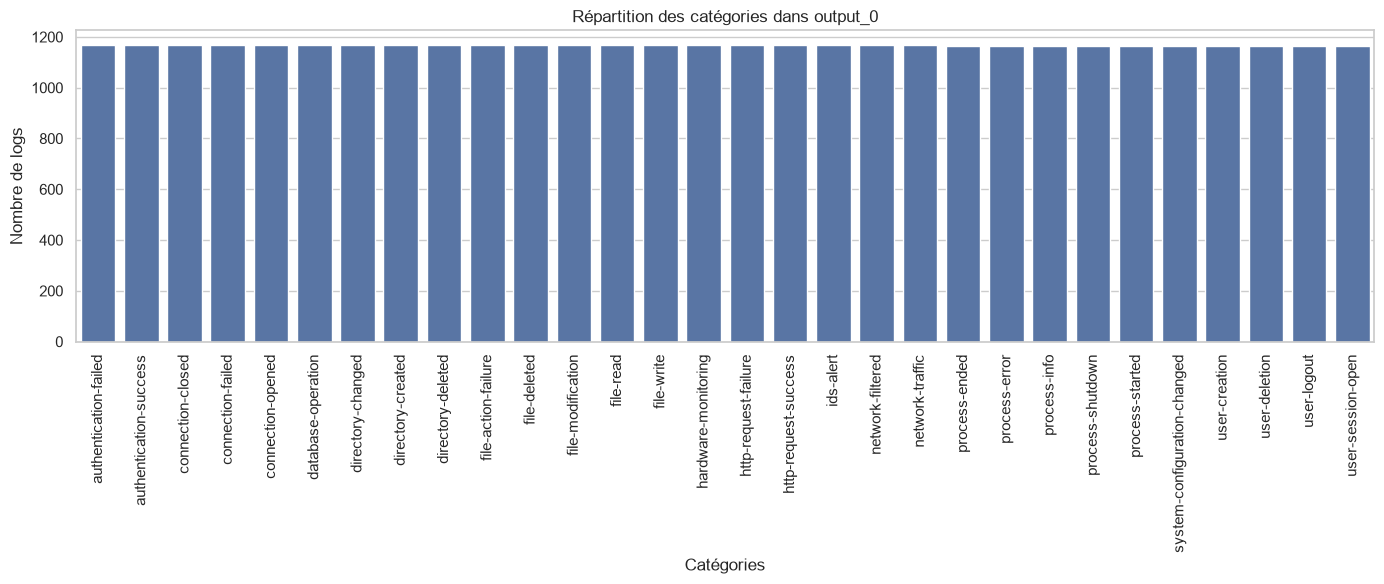

In [22]:
plt.figure(figsize=(14, 6))

sns.barplot(
    x=categories.index,
    y=categories.values
)

plt.title("Répartition des catégories dans output_0")
plt.xlabel("Catégories")
plt.ylabel("Nombre de logs")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

,output_0.log,output_0.1.log,output_0.2.log,output_0.3.log,output_0.4.log,output_0.5.log
category,,,,,,
authentication-failed,1167,1167,1167,1167,1167,1167
authentication-success,1167,1167,1167,1167,1167,1167
connection-closed,1167,1167,1167,1167,1167,1167
connection-failed,1167,1167,1167,1167,1167,1167
connection-opened,1167,1167,1167,1167,1167,1167
database-operation,1167,1167,1167,1167,1167,1167
directory-changed,1167,1167,1167,1167,1167,1167
directory-created,1167,1167,1167,1167,1167,1167
directory-deleted,1167,1167,1167,1167,1167,1167


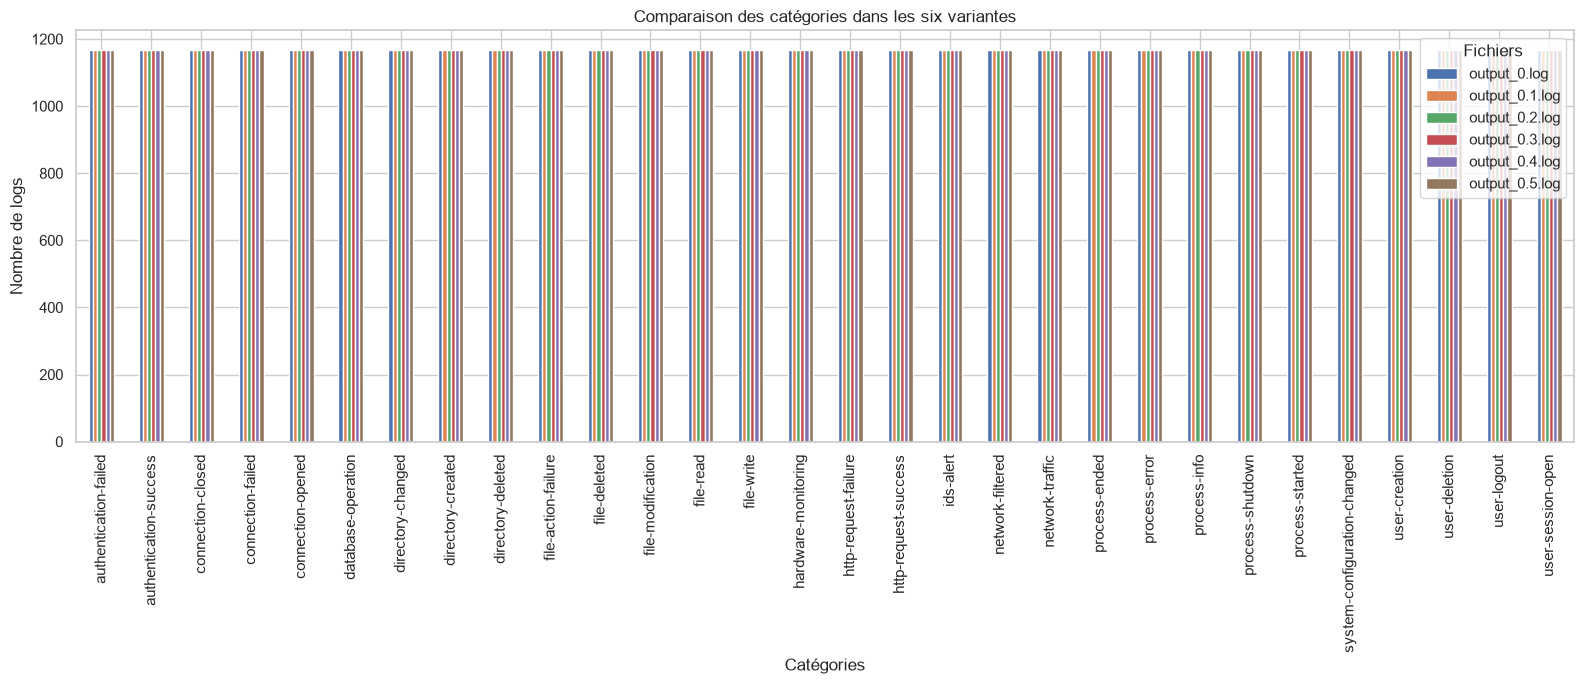

In [23]:
category_counts = {}

for name, df in datasets.items():

    category_counts[name] = df["category"].value_counts()

category_comparison = pd.DataFrame(category_counts).fillna(0)

display(category_comparison)

category_comparison.plot(
    kind="bar",
    figsize=(16, 7)
)

plt.title("Comparaison des catégories dans les six variantes")
plt.xlabel("Catégories")
plt.ylabel("Nombre de logs")
plt.xticks(rotation=90)
plt.legend(title="Fichiers")

plt.tight_layout()
plt.show()

In [24]:
for name, df in datasets.items():

    df["log_length"] = df["log"].astype(str).apply(len)

    print("\nFichier :", name)

    print(df["log_length"].describe())


Fichier : output_0.log
count    35000.000000
mean       150.894343
std        133.200734
min         24.000000
25%         82.000000
50%        114.000000
75%        160.000000
max       1041.000000
Name: log_length, dtype: float64

Fichier : output_0.1.log
count    35000.000000
mean       155.036629
std        139.390466
min         24.000000
25%         83.000000
50%        117.000000
75%        166.000000
max       1122.000000
Name: log_length, dtype: float64

Fichier : output_0.2.log
count    35000.000000
mean       159.656143
std        144.847466
min         24.000000
25%         87.000000
50%        120.000000
75%        172.000000
max       1207.000000
Name: log_length, dtype: float64

Fichier : output_0.3.log
count    35000.000000
mean       164.182514
std        152.401205
min         23.000000
25%         88.000000
50%        122.000000
75%        176.000000
max       1334.000000
Name: log_length, dtype: float64

Fichier : output_0.4.log
count    35000.000000
mean       167